**RANDOM FOREST**

Accuracy  : 100.0
Precision : 100.0
Recall    : 100.0
F1-score  : 100.0

Confusion Matrix:
[[205   0   0]
 [  0 171   0]
 [  0   0 104]]


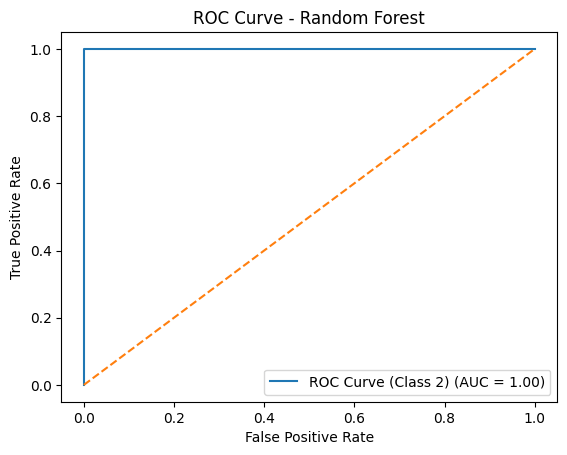

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_curve,
    auc
)

data = pd.read_csv('/content/drive/MyDrive/Pancreatic Cancer Prediction using ML/pancreatic_600_risk123.csv')

X = data.drop(['diagnosis', 'sample_id'], axis=1)
y = data['diagnosis']

X = pd.get_dummies(X, drop_first=True)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

rf = RandomForestClassifier(
    n_estimators=500,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42
)

rf.fit(X_train, y_train)

y_pred = rf.predict(X_train)

target_class_for_roc = rf.classes_[1]

y_prob = rf.predict_proba(X_train)[:, 1]

accuracy = accuracy_score(y_train, y_pred)
precision = precision_score(y_train, y_pred, average='weighted')
recall = recall_score(y_train, y_pred, average='weighted')
f1 = f1_score(y_train, y_pred, average='weighted')

print("Accuracy  :", accuracy * 100)
print("Precision :", precision * 100)
print("Recall    :", recall * 100)
print("F1-score  :", f1 * 100)

cm = confusion_matrix(y_train, y_pred)
print("\nConfusion Matrix:")
print(cm)

y_train_binary_for_roc = (y_train == target_class_for_roc).astype(int)

fpr, tpr, _ = roc_curve(y_train_binary_for_roc, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, label=f'ROC Curve (Class {target_class_for_roc}) (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Random Forest')
plt.legend(loc='lower right')
plt.show()
